# PyTorch fundamentals: from tensors to a training loop
We will learn the mechanics on tiny synthetic examples before using Citi Bike data in notebook 06. A neural network is a parameterized function: it transforms input **features** into an output prediction. Training changes its parameters to reduce a loss.

Official references: [PyTorch basics](https://docs.pytorch.org/tutorials/beginner/basics/intro.html), [autograd](https://docs.pytorch.org/tutorials/beginner/basics/autogradqs_tutorial.html), [optimization](https://docs.pytorch.org/tutorials/beginner/basics/optimization_tutorial.html).

## Environment
Use the existing **CityPulse AI (.venv)** kernel. Install with `.venv/bin/python -m pip install -e '.[neural,forecasting,notebooks,dev]'` from the project root. We use CPU, float32, fixed seeds and one CPU thread. No datasets or cloud operations are needed for these fundamentals.

On this Mac, keep the existing XGBoost OpenMP launch setting when starting Jupyter:
```bash
export DYLD_LIBRARY_PATH="$PWD/.venv/lib/python3.14/site-packages/sklearn/.dylibs${DYLD_LIBRARY_PATH:+:$DYLD_LIBRARY_PATH}"
.venv/bin/python -m jupyter lab
```
Python 3.14.7 and the existing environment were retained; PyTorch 2.14.1 has a matching macOS ARM wheel.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.preprocessing import StandardScaler
from IPython.display import display

torch.manual_seed(42)
torch.set_num_threads(1)
torch.use_deterministic_algorithms(True)
print('PyTorch:', torch.__version__, '| device: cpu')

Matplotlib is building the font cache; this may take a moment.


PyTorch: 2.14.1 | device: cpu


## 1. Tensors, shapes and dtypes
A tensor is an array with a dtype and a device. Like NumPy, tensors support numerical array operations. PyTorch also supports automatic differentiation and accelerator devices; today all tensors stay on CPU.

A scalar has zero dimensions, a vector one, and a matrix two. A batch of 24 hourly rows with nine features has shape `(24, 9)`. A one-output regression model returns `(24, 1)`. Keep targets in that same shape to avoid accidental broadcasting. Gradient calculations require floating-point or complex tensors, not integer counts.

In [2]:
scalar = torch.tensor(3.0)
vector = torch.tensor([1, 2, 3], dtype=torch.int64)
matrix = torch.tensor([[1, 2], [3, 4]], dtype=torch.float32)
batch = torch.zeros(24, 9, dtype=torch.float32)
display(pd.DataFrame([{'name': name, 'shape': tuple(t.shape), 'dimensions': t.ndim,
                       'dtype': str(t.dtype), 'device': str(t.device)}
                      for name, t in [('scalar', scalar), ('vector', vector),
                                      ('matrix', matrix), ('forecast batch', batch)]]))
array = np.array([1., 2.], dtype=np.float32)
shared = torch.from_numpy(array)  # Shares CPU memory with this NumPy array.
copied = torch.tensor(array)     # Copies the values.
array[0] = 9.
print('NumPy:', array, '| shared tensor:', shared, '| copied tensor:', copied)
assert shared[0] == 9 and copied[0] == 1

,name,shape,dimensions,dtype,device
0,scalar,(),0,torch.float32,cpu
1,vector,"(3,)",1,torch.int64,cpu
2,matrix,"(2, 2)",2,torch.float32,cpu
3,forecast batch,"(24, 9)",2,torch.float32,cpu


NumPy: [9. 2.] | shared tensor: tensor([9., 2.]) | copied tensor: tensor([1., 2.])


## 2. `requires_grad` and automatic differentiation
With `requires_grad=True`, PyTorch records operations in a computation graph. Calling `backward()` applies the chain rule and puts derivatives in `.grad`. For `y = x²` at `x = 3`, the derivative is `2x = 6`. Gradients accumulate, so a training loop must clear them before each update.

In [3]:
x = torch.tensor(3.0, requires_grad=True)
y = x ** 2
y.backward()
print('y:', y.item(), '| dy/dx:', x.grad.item())
assert x.grad.item() == 6.0
x.grad = None  # Clear this gradient before another calculation.

y: 9.0 | dy/dx: 6.0


## 3. Weights, biases, linear layers and ReLU
A linear layer computes `output = input @ weight.T + bias`. Training learns weights and biases. Without nonlinear activations, a stack of linear layers is still a linear function. **ReLU** returns `max(0, x)` and lets stacked layers represent nonlinear relationships. A forward pass simply computes a prediction; it does not change any weights.

In [4]:
linear = nn.Linear(1, 1)
with torch.no_grad():
    linear.weight.fill_(0.5)
    linear.bias.fill_(0.1)
inputs = torch.tensor([[2.0], [4.0]])
print('Weights:', linear.weight.detach(), '| bias:', linear.bias.detach())
print('Forward predictions:', linear(inputs).detach())
print('ReLU:', nn.ReLU()(torch.tensor([-2.0, 0.0, 3.0])))
network = nn.Sequential(nn.Linear(9, 32), nn.ReLU(), nn.Linear(32, 16), nn.ReLU(), nn.Linear(16, 1))
print(network)
assert network(batch).shape == (24, 1)

Weights: tensor([[0.5000]]) | bias: tensor([0.1000])
Forward predictions: tensor([[1.1000],
        [2.1000]])
ReLU: tensor([0., 0., 3.])
Sequential(
  (0): Linear(in_features=9, out_features=32, bias=True)
  (1): ReLU()
  (2): Linear(in_features=32, out_features=16, bias=True)
  (3): ReLU()
  (4): Linear(in_features=16, out_features=1, bias=True)
)


## 4. MSE, backpropagation and a visible optimizer step
**Mean squared error (MSE)** is the mean of `(prediction − target)²`; large errors receive more weight. `loss.backward()` computes gradients but does not update parameters. An optimizer's `step()` performs the update.

For this one-row example, start with weight 1 and bias 0, input 2 and target 4. The prediction is 2 and MSE is 4. Gradients are −8 for the weight and −4 for the bias. Simple gradient descent uses `parameter = parameter − learning_rate × gradient`. At learning rate 0.1, the new weight is 1.8 and bias is 0.4. We use SGD here so the arithmetic is visible; the forecasting MLP uses Adam.

In [5]:
worked = nn.Linear(1, 1)
with torch.no_grad():
    worked.weight.fill_(1.0)
    worked.bias.zero_()
optimizer = torch.optim.SGD(worked.parameters(), lr=0.1)
input_row, target_row = torch.tensor([[2.0]]), torch.tensor([[4.0]])
optimizer.zero_grad(set_to_none=True)
before_weight, before_bias = worked.weight.item(), worked.bias.item()
loss = nn.MSELoss()(worked(input_row), target_row)
loss.backward()
weight_gradient, bias_gradient = worked.weight.grad.item(), worked.bias.grad.item()
optimizer.step()
with torch.no_grad():
    after_loss = nn.MSELoss()(worked(input_row), target_row).item()
display(pd.DataFrame({'parameter': ['weight', 'bias'],
                      'before': [before_weight, before_bias],
                      'gradient': [weight_gradient, bias_gradient],
                      'after': [worked.weight.item(), worked.bias.item()]}))
print('Loss before:', loss.item(), '| loss after:', after_loss)
assert abs(worked.weight.item() - 1.8) < 1e-6
assert abs(worked.bias.item() - 0.4) < 1e-6

,parameter,before,gradient,after
0,weight,1.0,-8.0,1.8
1,bias,0.0,-4.0,0.4


Loss before: 4.0 | loss after: 0.0


## 5. Adam, epochs, batches and the training loop
Adam adapts step sizes using running estimates of gradient averages and squared gradients. The learning rate remains a hyperparameter. A **batch** is a small group of training rows; one **epoch** is one pass through all training rows. `DataLoader` creates batches. Shuffling January's supervised rows is safe after constructing causal features and splitting chronologically; we never shuffle rows across the chronological split.

The loop below fits synthetic `y = 3x + 2` with a small network for 40 epochs. Each batch follows: clear gradients → forward pass → loss → backward pass → optimizer step. The reported epoch loss is evaluated on all rows after the updates.

First completed epoch MSE: 5.01615571975708 | final MSE: 0.004738650284707546


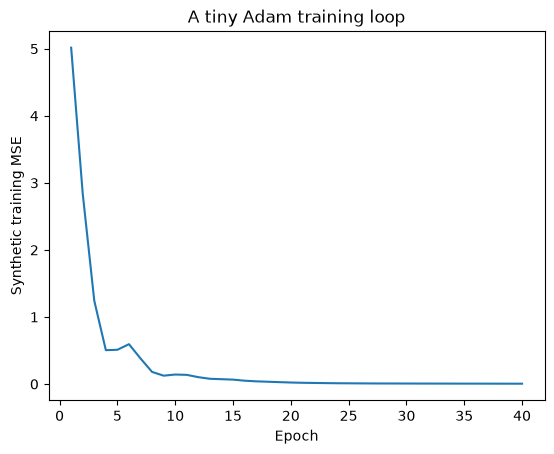

In [6]:
torch.manual_seed(42)
toy_x = torch.linspace(-1, 1, 16).reshape(-1, 1)
toy_y = 3 * toy_x + 2
toy = nn.Sequential(nn.Linear(1, 8), nn.ReLU(), nn.Linear(8, 1))
loader = DataLoader(TensorDataset(toy_x, toy_y), batch_size=4, shuffle=True,
                    generator=torch.Generator().manual_seed(42), num_workers=0)
adam = torch.optim.Adam(toy.parameters(), lr=0.03)
losses = []
for epoch in range(40):
    toy.train()
    for features, targets in loader:
        adam.zero_grad(set_to_none=True)
        batch_loss = nn.MSELoss()(toy(features), targets)
        batch_loss.backward()
        adam.step()
    toy.eval()
    with torch.no_grad():
        losses.append(nn.MSELoss()(toy(toy_x), toy_y).item())
print('First completed epoch MSE:', losses[0], '| final MSE:', losses[-1])
plt.plot(range(1, 41), losses)
plt.xlabel('Epoch'); plt.ylabel('Synthetic training MSE'); plt.title('A tiny Adam training loop')
plt.show()

## 6. `train()`, `eval()` and `torch.no_grad()`
`train()` and `eval()` control module behavior such as dropout and batch normalization; they do not turn gradient recording on or off. `torch.no_grad()` turns off graph recording for inference, reducing memory use. Our first MLP has only linear/ReLU layers, so its numerical behavior does not change between these modes, but using the modes explicitly is good practice.

A dropout example makes the mode distinction visible: it randomly masks values during training and keeps them during evaluation.

In [7]:
dropout = nn.Dropout(0.5)
dropout.train()
print('Training dropout:', dropout(torch.ones(8)))
dropout.eval()
print('Evaluation dropout:', dropout(torch.ones(8)))
toy.eval()
print('eval() alone still records gradients:', toy(toy_x).requires_grad)
with torch.no_grad():
    toy_predictions = toy(toy_x)
print('no_grad predictions record gradients:', toy_predictions.requires_grad)
assert not toy_predictions.requires_grad

Training dropout: tensor([2., 0., 2., 0., 0., 2., 2., 0.])
Evaluation dropout: tensor([1., 1., 1., 1., 1., 1., 1., 1.])
eval() alone still records gradients: True
no_grad predictions record gradients: False


## 7. Why scaling matters
Raw hourly demand may be thousands while a sine feature lies between −1 and 1. Unequal scales can make optimization harder. Standardization computes `(value − training_mean) / training_standard_deviation`. Fit the scaler on training rows only, then apply those stored statistics to validation/test.

We also standardize the demand target for training, then reverse that transform before reporting errors in rides/hour. A standardized target may be negative even though raw demand is nonnegative. In notebook 06, scalers are fitted on January only; future values never change the means or standard deviations.

In [8]:
toy_features = pd.DataFrame({'demand_lag': [1000., 2000., 3000.],
                             'cyclic_feature': [-1., 0., 1.]})
scaler = StandardScaler().fit(toy_features)  # These three rows are toy training data.
display(toy_features)
display(pd.DataFrame(scaler.transform(toy_features), columns=toy_features.columns))
print('Stored training means:', scaler.mean_)
print('Apply training scale to a new row:', scaler.transform(pd.DataFrame(
    {'demand_lag': [4000.], 'cyclic_feature': [0.5]})))

,demand_lag,cyclic_feature
0,1000.0,-1.0
1,2000.0,0.0
2,3000.0,1.0


,demand_lag,cyclic_feature
0,-1.224745,-1.224745
1,0.000000,0.000000
2,1.224745,1.224745


Stored training means: [2000.    0.]
Apply training scale to a new row: [[2.44948974 0.61237244]]


## Continue in notebook 06
You have now executed tensor operations, autograd, linear/ReLU forward passes, a visible weight update, an Adam mini-batch loop, inference modes and scaling. Next we will apply those mechanics to the same leakage-safe Citi Bike features. A neural network is not automatically better than our seasonal baselines or XGBoost; we will compare measured errors.